<a href="https://colab.research.google.com/github/vhvaldiviesor/Programacion-para-analitica-descriptiva-y-predictiva/blob/main/269711_ClassImbalance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tratamiento de Clases No Balanceadas: Clasificación con SVM

**Programación para Analítica Descriptiva y Predictiva — MIAAD, UACJ**

**Nombre: Victor Hugo Valdivieso Rodriguez**

**Matrícula: 269711**

---

## Objetivo

Aplicar técnicas de aprendizaje automático para el tratamiento de clases no balanceadas, utilizando el conjunto de datos `compustat.csv` como problema de clasificación real.

**Sobre los datos.** El conjunto tiene 21 atributos: la primera columna (`idx`) es un índice y se ignora durante el análisis y entrenamiento; la última columna (`label`) es la etiqueta de clase; las 20 columnas restantes (`at0`...`at19`) son las variables predictoras.

## 1. Análisis Exploratorio de Datos (AED)

- Un diagrama de barras mostrando la distribución de las clases.
- Diagramas de densidad KDE para los atributos 5 y 13.
- Un análisis breve sobre el nivel de desbalance presente en el conjunto de datos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
VERDE = "#4C9F70"
COLORES_CLASE = {0: AZUL, 1: NARANJA}

df = pd.read_csv("compustat.csv")
print(f"Dimensiones: {df.shape}")
df.head()

Dimensiones: (13657, 22)


,idx,at0,at1,at2,at3,at4,at5,at6,at7,at8,...,at11,at12,at13,at14,at15,at16,at17,at18,at19,label
0,0,0.076753,0.066548,0.132170,4.257882,0.771988,0.669344,0.076278,2.898450,6.081867,...,2.052378,0.372113,0.322636,0.250182,1.153351,0.451476,0.590680,0.512143,0.076278,0
1,1,0.097633,0.087736,0.162879,4.141787,0.781934,0.702665,0.082633,2.947445,6.272092,...,1.968984,0.371728,0.334043,0.231646,1.112813,0.409376,0.593143,0.533012,0.056273,0
2,2,0.025683,0.022020,0.152882,3.140505,0.698522,0.598883,0.097905,2.971928,6.508112,...,1.374306,0.305678,0.262075,0.220100,1.166375,0.487141,0.476098,0.408186,0.050251,0
3,3,0.011354,0.008987,0.165670,2.927575,0.699374,0.553558,0.107831,2.955952,6.588417,...,1.173407,0.280317,0.221873,0.245524,1.263416,0.487903,0.460482,0.364474,0.047244,0
4,4,0.001675,0.001212,0.155509,3.120983,0.689971,0.499122,0.098458,2.896668,6.607998,...,1.069792,0.236504,0.171086,0.271291,1.382369,0.464594,0.468896,0.339197,0.042986,0


In [2]:
# El índice (idx) se descarta; label es la variable objetivo; el resto son predictoras
X = df.drop(columns=["idx", "label"])
y = df["label"]

print(f"X: {X.shape} ({list(X.columns)})")
print(f"y: {y.shape}")
print(f"\n¿Valores nulos? {df.isna().sum().sum()}")

X: (13657, 20) (['at0', 'at1', 'at2', 'at3', 'at4', 'at5', 'at6', 'at7', 'at8', 'at9', 'at10', 'at11', 'at12', 'at13', 'at14', 'at15', 'at16', 'at17', 'at18', 'at19'])
y: (13657,)

¿Valores nulos? 0


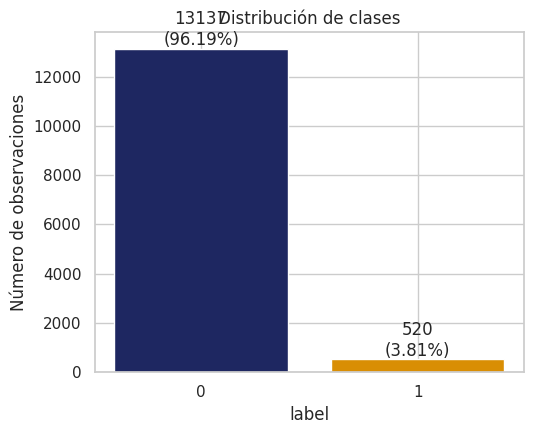

label
0    13137
1      520
Name: count, dtype: int64
label
0    96.19
1     3.81
Name: proportion, dtype: float64

Razón clase mayoritaria / minoritaria: 25.26 : 1


In [3]:
conteo_clases = y.value_counts().sort_index()
porcentaje_clases = y.value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(5.5, 4.5))
plt.bar(conteo_clases.index.astype(str), conteo_clases.values,
        color=[COLORES_CLASE[c] for c in conteo_clases.index])
plt.xlabel("label")
plt.ylabel("Número de observaciones")
plt.title("Distribución de clases")
for i, v in enumerate(conteo_clases.values):
    plt.text(i, v + 150, f"{v}\n({porcentaje_clases.values[i]:.2f}%)", ha="center")
plt.tight_layout()
plt.show()

print(conteo_clases)
print(porcentaje_clases.round(2))
print(f"\nRazón clase mayoritaria / minoritaria: {conteo_clases[0] / conteo_clases[1]:.2f} : 1")

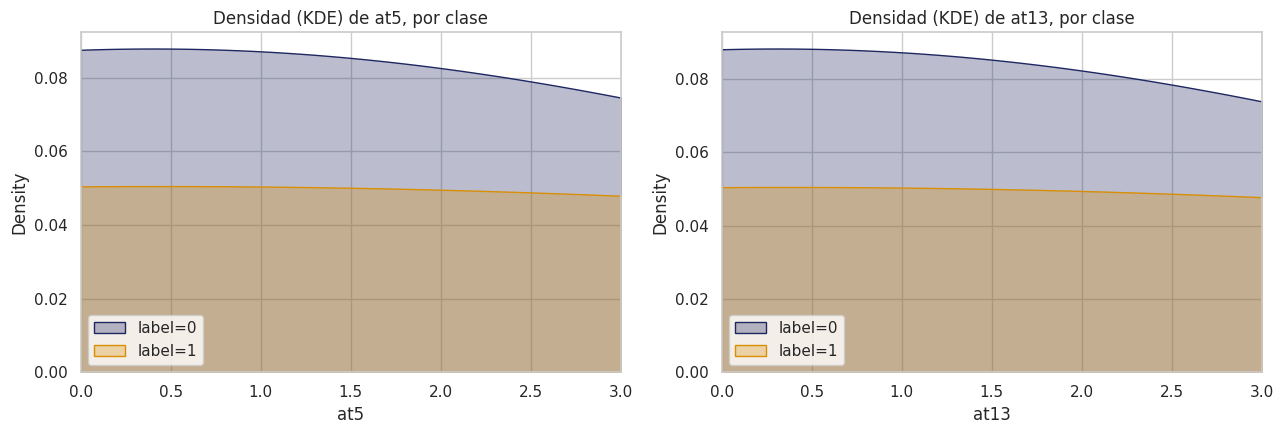

label                  0           1
at5  count  13137.000000  520.000000
     mean       0.833744    2.516887
     std       30.105511   27.190909
     min        0.000000    0.033323
     25%        0.233101    0.213198
     50%        0.327258    0.317003
     75%        0.468160    0.450435
     max     3296.157360  510.151970
at13 count  13137.000000  520.000000
     mean       0.723156    2.441538
     std       29.961983   27.196657
     min       -7.927344    0.022419
     25%        0.162668    0.155404
     50%        0.237302    0.222521
     75%        0.352671    0.351959
     max     3296.157360  510.151970


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, col in zip(axes, ["at5", "at13"]):
    for clase, color in COLORES_CLASE.items():
        sns.kdeplot(df.loc[df["label"] == clase, col], ax=ax, color=color,
                    label=f"label={clase}", fill=True, alpha=0.3, clip=(0, 3))
    ax.set_title(f"Densidad (KDE) de {col}, por clase")
    ax.set_xlim(0, 3)
    ax.legend()

plt.tight_layout()
plt.show()

print(df.groupby("label")[["at5", "at13"]].describe().T)

**Análisis del desbalance.** El conjunto tiene 13,657 observaciones: 13,137 de clase 0 (96.19%) y solo 520 de clase 1 (3.81%), una razón de 25.26:1. Es un desbalance **severo**: por cada observación de la clase minoritaria hay más de 25 de la mayoritaria. Esto es relevante porque un modelo que simplemente prediga siempre la clase 0 ya acertaría el 96.19% de las veces sin haber aprendido nada útil sobre la clase 1 — el riesgo central que se explora en el resto de la actividad.

Sobre `at5` y `at13`: ambas variables tienen una distribución muy concentrada cerca de 0 con una cola larga hacia la derecha (hay valores extremos hasta 3,296, fuera del rango de la gráfica, que se recortó en 3 para poder apreciar la forma de la densidad donde está la mayoría de los datos). Las densidades de clase 0 y clase 1 se parecen bastante en forma y en dónde se concentra la masa (la mediana de ambas clases es similar), aunque la clase 1 tiene una media más alta en ambas variables, señal de que unos cuantos valores extremos de la clase minoritaria jalan el promedio — consistente con que `at5` y `at13` parecen ser razones financieras con valores atípicos propios de empresas en situaciones inusuales (que es, probablemente, justo el tipo de empresa que cae en la clase minoritaria).

## 2. Modelo Base

Entrenar un modelo baseline utilizando:

```python
Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])
```

Este modelo deberá entrenarse sin aplicar métodos de tratamiento de desbalance y servirá como referencia para comparar los resultados posteriores.

In [5]:
# Validación cruzada estratificada de 5 particiones, consistente con la parte 4,
# para que el modelo base sea comparable en las mismas condiciones que los modelos balanceados.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

pipe_base = ImbPipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale")),
])

resultados_base = cross_validate(pipe_base, X, y, cv=cv, scoring=scoring)

print("Resultados por fold:")
for m in scoring:
    print(f"  {m}: {np.round(resultados_base['test_'+m], 4)}")

print("\nPromedio ± desviación estándar (ddof=1):")
for m in scoring:
    media = resultados_base["test_" + m].mean()
    desv = resultados_base["test_" + m].std(ddof=1)
    print(f"  {m}: {media:.4f} ± {desv:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Resultados por fold:
  accuracy: [0.9619 0.9619 0.9623 0.9627 0.9623]
  precision: [0. 0. 1. 1. 1.]
  recall: [0.     0.     0.0096 0.0192 0.0096]
  f1: [0.     0.     0.019  0.0377 0.019 ]

Promedio ± desviación estándar (ddof=1):
  accuracy: 0.9622 ± 0.0003
  precision: 0.6000 ± 0.5477
  recall: 0.0077 ± 0.0080
  f1: 0.0152 ± 0.0158


**Observación preliminar.** La exactitud (accuracy) del modelo base es altísima (≈96.22%), pero la precisión y el recall varían muchísimo entre folds (desviaciones estándar grandes para ser promedios de solo 5 valores): en varios folds el modelo predice positivo (clase 1) para 0 o 1 observaciones nada más, así que una sola predicción acertada o fallida cambia por completo la precisión de ese fold. Esto ya es una señal de alerta de que el modelo base, aunque "exacto", prácticamente no está detectando la clase minoritaria; se profundiza en la parte 5.

## 3. Tratamiento de Clases No Balanceadas

Aplicar y comparar los siguientes métodos:

- SMOTEENN
- One-Sided Selection

Para cada método:

- Mostrar la nueva distribución de clases después del balanceo.
- Entrenar nuevamente el modelo SVM utilizando los datos balanceados.

Distribución original: {0: np.int64(13137), 1: np.int64(520)}
Distribución después de SMOTEENN: {0: np.int64(11888), 1: np.int64(13080)}


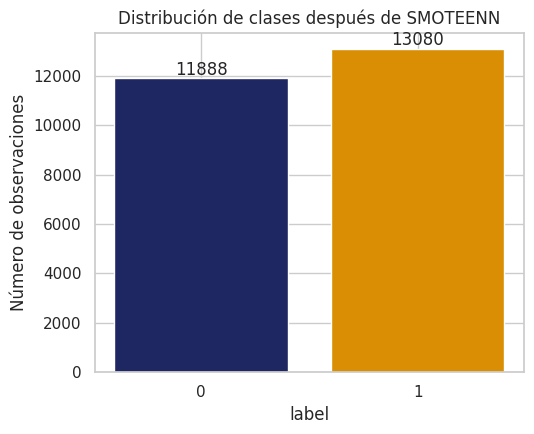

In [6]:
# SMOTEENN combina sobremuestreo (SMOTE, genera ejemplos sintéticos de la clase minoritaria)
# con limpieza (ENN, elimina observaciones de ambas clases cuyos vecinos son mayoritariamente
# de la otra clase). Se aplica aquí una sola vez sobre todo el dataset solo para ILUSTRAR cómo
# cambia la distribución; en la evaluación real (parte 4) el resampling va dentro del Pipeline
# de cada fold, para no filtrar información de prueba hacia el entrenamiento.
smoteenn_demo = SMOTEENN(random_state=42)
X_smoteenn_demo, y_smoteenn_demo = smoteenn_demo.fit_resample(X, y)

print("Distribución original:", dict(y.value_counts().sort_index()))
print("Distribución después de SMOTEENN:", dict(y_smoteenn_demo.value_counts().sort_index()))

plt.figure(figsize=(5.5, 4.5))
conteo_sm = y_smoteenn_demo.value_counts().sort_index()
plt.bar(conteo_sm.index.astype(str), conteo_sm.values, color=[COLORES_CLASE[c] for c in conteo_sm.index])
plt.xlabel("label")
plt.ylabel("Número de observaciones")
plt.title("Distribución de clases después de SMOTEENN")
for i, v in enumerate(conteo_sm.values):
    plt.text(i, v + 150, str(v), ha="center")
plt.tight_layout()
plt.show()

Distribución original: {0: np.int64(13137), 1: np.int64(520)}
Distribución después de One-Sided Selection: {0: np.int64(12994), 1: np.int64(520)}


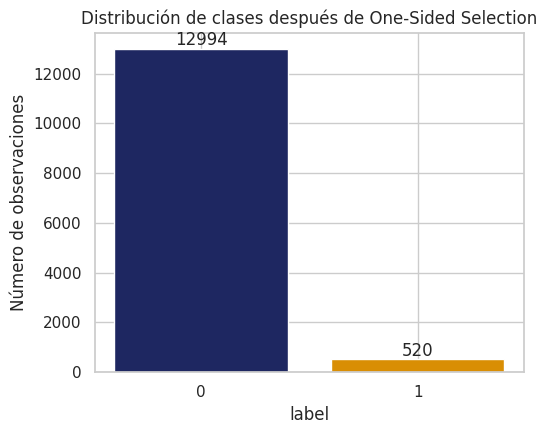

In [7]:
# One-Sided Selection es un método de SUBmuestreo: solo elimina observaciones de la clase
# mayoritaria (las que son "ruido" o están cerca de la frontera de decisión vía Tomek links
# y la regla 1-NN condensada); nunca toca ni agrega observaciones de la clase minoritaria.
oss_demo = OneSidedSelection(random_state=42)
X_oss_demo, y_oss_demo = oss_demo.fit_resample(X, y)

print("Distribución original:", dict(y.value_counts().sort_index()))
print("Distribución después de One-Sided Selection:", dict(y_oss_demo.value_counts().sort_index()))

plt.figure(figsize=(5.5, 4.5))
conteo_oss = y_oss_demo.value_counts().sort_index()
plt.bar(conteo_oss.index.astype(str), conteo_oss.values, color=[COLORES_CLASE[c] for c in conteo_oss.index])
plt.xlabel("label")
plt.ylabel("Número de observaciones")
plt.title("Distribución de clases después de One-Sided Selection")
for i, v in enumerate(conteo_oss.values):
    plt.text(i, v + 150, str(v), ha="center")
plt.tight_layout()
plt.show()

**Observación.** SMOTEENN transforma la distribución de forma drástica: pasa de 13,137/520 a 11,888/13,080 (prácticamente balanceado, y de hecho termina con un poco más de clase 1 que de clase 0, porque ENN eliminó más observaciones "ruidosas" de la clase mayoritaria que de la minoritaria al limpiar después de sobremuestrear). One-Sided Selection, en cambio, apenas cambia la distribución: de 13,137/520 pasa a 12,994/520 — solo elimina 143 observaciones de la clase mayoritaria (las más redundantes o ruidosas cerca de la frontera) y no toca la clase minoritaria en absoluto, así que la razón de desbalance sigue siendo casi la misma (24.99:1 en vez de 25.26:1). Esta diferencia de magnitud entre ambos métodos es clave para interpretar los resultados de la parte 5: cabe esperar que OSS, al dejar el desbalance prácticamente intacto, tenga un efecto mucho menor sobre el comportamiento del modelo que SMOTEENN.

## 4. Entrenamiento y Evaluación del Modelo

- Utilizar validación cruzada estratificada de 5 particiones.
- Implementar el flujo de trabajo utilizando Pipeline para evitar data leakage.
- Incorporar escalado de datos dentro del Pipeline.
- Utilizar SVM con kernel RBF.

In [8]:
# El escalado y el resampling van DENTRO del Pipeline de imbalanced-learn: así, en cada fold
# de la validación cruzada, el scaler y el método de balanceo se ajustan SOLO con los datos de
# entrenamiento de ese fold, y el fold de prueba nunca participa en el ajuste de ninguno de los
# dos pasos. Esto evita el data leakage que ocurriría si se balanceara o escalara el dataset
# completo antes de dividirlo en folds (el modelo "vería" indirectamente información del fold
# de prueba a través de las estadísticas de escalado o de los ejemplos sintéticos/eliminados).

pipe_smoteenn = ImbPipeline([
    ("scaler", StandardScaler()),
    ("resample", SMOTEENN(random_state=42)),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale")),
])

pipe_oss = ImbPipeline([
    ("scaler", StandardScaler()),
    ("resample", OneSidedSelection(random_state=42)),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale")),
])

resultados_smoteenn = cross_validate(pipe_smoteenn, X, y, cv=cv, scoring=scoring)
resultados_oss = cross_validate(pipe_oss, X, y, cv=cv, scoring=scoring)

for nombre, res in [("SMOTEENN", resultados_smoteenn), ("One-Sided Selection", resultados_oss)]:
    print(f"\n=== {nombre} ===")
    for m in scoring:
        media = res["test_" + m].mean()
        desv = res["test_" + m].std(ddof=1)
        print(f"  {m}: {media:.4f} ± {desv:.4f}")


=== SMOTEENN ===
  accuracy: 0.8112 ± 0.0050
  precision: 0.1439 ± 0.0101
  recall: 0.8000 ± 0.0558
  f1: 0.2439 ± 0.0171

=== One-Sided Selection ===
  accuracy: 0.9622 ± 0.0002
  precision: 0.8333 ± 0.2357
  recall: 0.0115 ± 0.0043
  f1: 0.0227 ± 0.0082


## 5. Evaluación de Resultados

Reportar y analizar al menos las siguientes métricas:

- Accuracy
- Precision
- Recall
- F1-score
- Matriz de confusión

Además:

- Comparar los resultados del modelo baseline contra los modelos balanceados.
- Generar una gráfica comparativa de métricas.
- Analizar si Accuracy es suficiente para evaluar el problema.

In [9]:
tabla_resultados = pd.DataFrame({
    "modelo": ["Baseline (sin balanceo)", "SMOTEENN", "One-Sided Selection"],
    "accuracy": [resultados_base["test_accuracy"].mean(), resultados_smoteenn["test_accuracy"].mean(), resultados_oss["test_accuracy"].mean()],
    "precision": [resultados_base["test_precision"].mean(), resultados_smoteenn["test_precision"].mean(), resultados_oss["test_precision"].mean()],
    "recall": [resultados_base["test_recall"].mean(), resultados_smoteenn["test_recall"].mean(), resultados_oss["test_recall"].mean()],
    "f1": [resultados_base["test_f1"].mean(), resultados_smoteenn["test_f1"].mean(), resultados_oss["test_f1"].mean()],
})
tabla_resultados

,modelo,accuracy,precision,recall,f1
0,Baseline (sin balanceo),0.962217,0.600000,0.007692,0.015166
1,SMOTEENN,0.811159,0.143910,0.800000,0.243934
2,One-Sided Selection,0.962217,0.833333,0.011538,0.022679


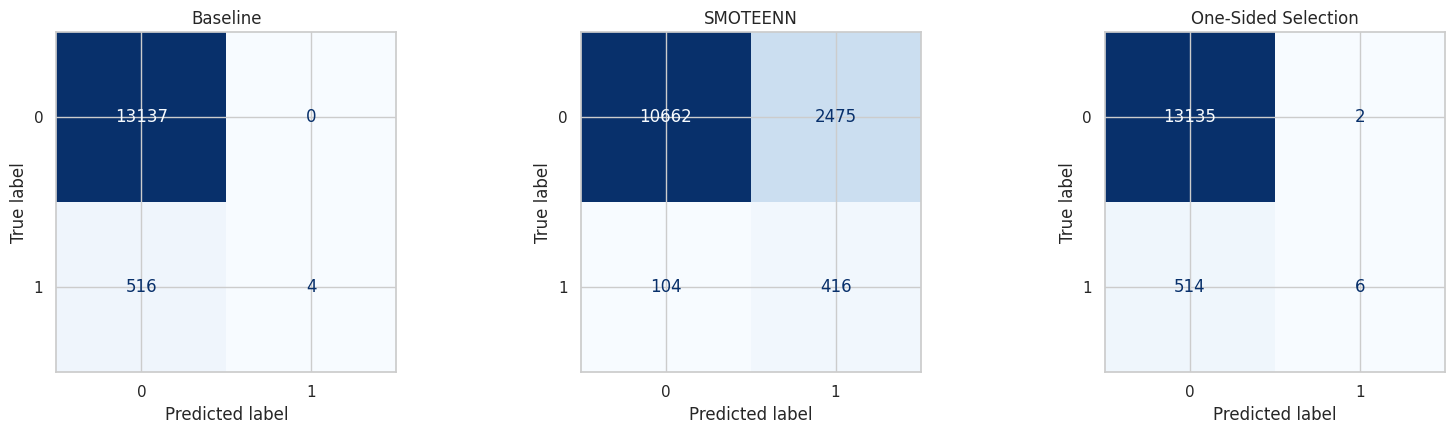

In [10]:
# Matrices de confusion agregadas: se usan las predicciones out-of-fold de cross_val_predict
# (cada observacion es predicha por el modelo del fold en el que quedo como prueba), que es la
# forma correcta de construir una matriz de confusion "global" sin filtrar informacion.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, nombre, pipe in zip(axes, ["Baseline", "SMOTEENN", "One-Sided Selection"], [pipe_base, pipe_smoteenn, pipe_oss]):
    y_pred = cross_val_predict(pipe, X, y, cv=cv)
    cm = confusion_matrix(y, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nombre)

plt.tight_layout()
plt.show()

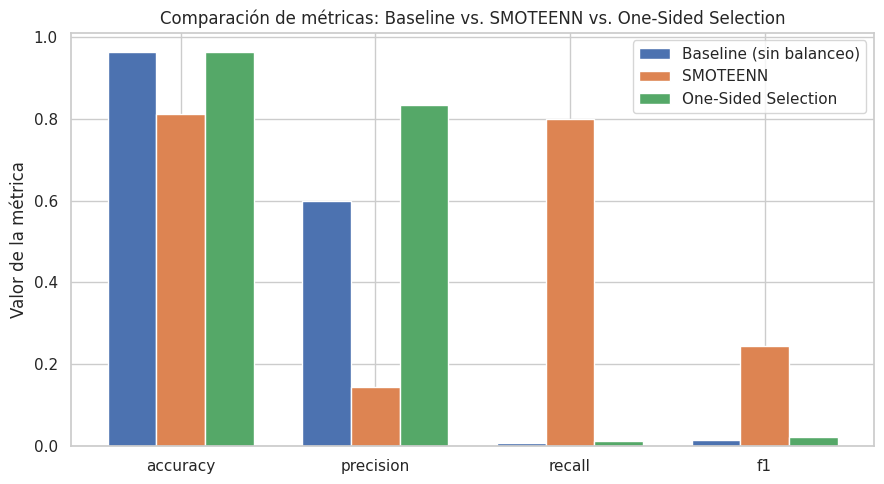

In [11]:
metricas = ["accuracy", "precision", "recall", "f1"]
x = np.arange(len(metricas))
ancho = 0.25

plt.figure(figsize=(9, 5))
for i, modelo in enumerate(tabla_resultados["modelo"]):
    valores = tabla_resultados.loc[tabla_resultados["modelo"] == modelo, metricas].values[0]
    plt.bar(x + (i - 1) * ancho, valores, width=ancho, label=modelo)

plt.xticks(x, metricas)
plt.ylabel("Valor de la métrica")
plt.title("Comparación de métricas: Baseline vs. SMOTEENN vs. One-Sided Selection")
plt.legend()
plt.tight_layout()
plt.show()

**Comparación de resultados.**

| Modelo | Accuracy | Precision | Recall | F1 |
| --- | --- | --- | --- | --- |
| Baseline (sin balanceo) | 0.9622 | ≈0.60 (muy inestable entre folds) | 0.0077 | 0.0152 |
| SMOTEENN | 0.8112 | 0.1439 | 0.8000 | 0.2439 |
| One-Sided Selection | 0.9622 | ≈0.83 (muy inestable entre folds) | 0.0115 | 0.0227 |

La matriz de confusión agregada (sobre las 13,657 observaciones, usando las predicciones fuera de muestra de cada fold) hace el problema evidente:

- **Baseline:** de las 520 observaciones de clase 1, el modelo detecta correctamente solo 4 (recall = 0.77%); las otras 516 las clasifica como clase 0. A cambio, nunca produce falsos positivos en la clase 0 (13,137 correctos).
- **One-Sided Selection:** prácticamente lo mismo que el baseline (6 de 520 detectados, recall = 1.15%), consistente con que esta técnica casi no modificó la distribución de clases (parte 3).
- **SMOTEENN:** detecta 416 de las 520 observaciones de clase 1 (recall = 80.00%), un salto enorme frente a los otros dos modelos, pero a costa de 2,475 falsos positivos sobre la clase 0 (precision = 14.39%) y una exactitud notablemente menor (81.12%).

**¿Es suficiente Accuracy para evaluar este problema?** No. El baseline y One-Sided Selection tienen la accuracy más alta de los tres modelos (96.22%), y sin embargo son, en la práctica, inútiles para el objetivo real del problema: detectar la clase minoritaria. Esto es el "accuracy paradox" clásico de problemas desbalanceados — con una razón de 25:1, un modelo que casi nunca predice la clase 1 ya obtiene una accuracy altísima simplemente por la composición del dataset, sin necesidad de haber aprendido nada útil. Accuracy trata un acierto en la clase mayoritaria exactamente igual que un acierto en la minoritaria, cuando en la mayoría de los problemas reales de clases desbalanceadas (fraude, impago, falla de equipo, etc.) es la clase minoritaria la que importa detectar. Recall, precision y F1, calculados sobre la clase de interés, son las métricas que realmente distinguen el comportamiento de los tres modelos en este caso.

## 6. Discusión y Conclusiones

Discutir:

- El impacto del desbalance sobre el desempeño del modelo.
- Las diferencias observadas entre SMOTEENN y One-Sided Selection.
- Qué método produjo los mejores resultados y por qué.

**El impacto del desbalance sobre el desempeño del modelo.** Con una razón de 25.26:1, el SVM baseline (entrenado sin ningún tratamiento de desbalance) aprendió, en la práctica, a predecir casi siempre la clase mayoritaria: el costo de equivocarse en la clase 1 (520 observaciones) pesa muy poco en la función de pérdida frente al costo de equivocarse en la clase 0 (13,137 observaciones), así que el modelo "decide" que casi nunca vale la pena arriesgarse a predecir clase 1. El resultado es una accuracy engañosamente alta (96.22%) con un recall casi nulo (0.77%): el modelo es, para el problema real de detectar la clase minoritaria, prácticamente inútil, aunque sus métricas globales se vean bien a primera vista.

**Diferencias entre SMOTEENN y One-Sided Selection.** Los dos métodos atacan el desbalance de forma fundamentalmente distinta. One-Sided Selection es un método de submuestreo conservador: solo elimina observaciones de la clase mayoritaria que son redundantes o ruidosas (vía Tomek links y la regla 1-NN condensada), sin tocar la clase minoritaria ni generar datos nuevos. En este dataset eso resultó en un cambio casi insignificante en la distribución (de 25.26:1 a 24.99:1), y por eso el modelo entrenado con esos datos se comportó casi igual que el baseline (recall = 1.15%, prácticamente sin mejora). SMOTEENN, en cambio, combina sobremuestreo sintético (SMOTE genera observaciones nuevas de la clase minoritaria, interpolando entre vecinos existentes) con una limpieza posterior (ENN elimina de ambas clases las observaciones cuyos vecinos son mayoritariamente de la otra clase). El resultado fue una distribución casi balanceada (11,888 vs. 13,080) y, con ella, un cambio radical en el comportamiento del modelo: recall de 80.00% a costa de bajar accuracy a 81.12% y precision a 14.39%. La diferencia de fondo es que OSS deja intacto el número de ejemplos de clase 1 de los que el modelo puede aprender, mientras que SMOTEENN sí le da al modelo muchos más ejemplos (sintéticos) de la clase minoritaria para aprender su patrón.

**¿Qué método produjo los mejores resultados y por qué?** Depende del criterio, pero para el objetivo típico de un problema de clases desbalanceadas (detectar la clase minoritaria, que suele ser la de interés real: empresas en dificultades, en este caso), **SMOTEENN fue claramente el mejor**: es el único de los tres modelos que logra un recall útil (80%) en vez de uno cercano a 0. El costo es una caída en precision y accuracy, es decir, más falsos positivos (2,475 observaciones de clase 0 marcadas como clase 1); pero en problemas donde no detectar un caso positivo es mucho más costoso que investigar un falso positivo (como suele ser el caso en riesgo financiero, fraude o fallas), ese es un intercambio razonable. One-Sided Selection, en este dataset, no resultó útil porque por su propio diseño (submuestreo conservador de la mayoría, sin generar ni priorizar ejemplos de la minoría) no tenía manera de corregir un desbalance tan extremo como 25:1 — su efecto habría sido más notorio en un desbalance más moderado. El baseline queda descartado por completo para el objetivo real del problema, a pesar de tener la accuracy "más alta" junto con OSS.